# **Hate Speech Classification**

Tujuan project: Membangun model klasifikasi biner menggunakan TF-IDF dan Support Vector Machine yang mampu mengklasifikasikan teks berbahasa Indonesia menjadi kelas hate speech dan non-hate speech.

## **Import Library**

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

## **Load Dataset**

In [48]:
# Membaca dataset hasil splitting
train_df = pd.read_csv('../dataset/processed/data_train.csv', encoding='latin-1')
test_df = pd.read_csv('../dataset/processed/data_test.csv', encoding='latin-1')

In [49]:
# Menampilkan informasi pada masing-masing dataset
print("Informasi dataset training")
train_df.info()

print("\nInformasi dataset testing")
test_df.info()

Informasi dataset training
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10281 entries, 0 to 10280
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Tweet   10281 non-null  object
 1   HS      10281 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 160.8+ KB

Informasi dataset testing
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2571 entries, 0 to 2570
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Tweet   2571 non-null   object
 1   HS      2571 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 40.3+ KB


In [50]:
# Memeriksa missing values pada masing-masing dataset
print("Missing Values Training:")
print(train_df[['Tweet', 'HS']].isnull().sum())

print("\nMissing Values Testing:")
print(test_df[['Tweet', 'HS']].isnull().sum())

Missing Values Training:
Tweet    0
HS       0
dtype: int64

Missing Values Testing:
Tweet    0
HS       0
dtype: int64


## **TF-IDF**

In [51]:
# Memisahkan fitur (X) dan target (y)
X_train = train_df['Tweet']
y_train = train_df['HS']

X_test = test_df['Tweet']
y_test = test_df['HS']

# Memeriksa bentuk data
print("Shape X_train:", X_train.shape)
print("Shape y_train:", y_train.shape)

print("\nShape X_test :", X_test.shape)
print("Shape y_test :", y_test.shape)

Shape X_train: (10281,)
Shape y_train: (10281,)

Shape X_test : (2571,)
Shape y_test : (2571,)


In [52]:
# Inisialisasi TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    sublinear_tf=True
)

In [53]:
# Fit dan transform hanya menggunakan data training
X_train_tfidf = tfidf.fit_transform(X_train)

print("TF-IDF Training berhasil")
print("Shape X_train_tfidf:", X_train_tfidf.shape)

TF-IDF Training berhasil
Shape X_train_tfidf: (10281, 101939)


In [54]:
# Transform data testing menggunakan vocabulary dan IDF dari training
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Testing berhasil dilakukan")
print("Shape X_test_tfidf:", X_test_tfidf.shape)

TF-IDF Testing berhasil dilakukan
Shape X_test_tfidf: (2571, 101939)


In [55]:
# Memastikan dimensi training dan testing konsisten
print("Dimensi TF-IDF Training:", X_train_tfidf.shape)
print("Dimensi TF-IDF Testing :", X_test_tfidf.shape)

# Memastikan jumlah fitur sama
assert X_train_tfidf.shape[1] == X_test_tfidf.shape[1]

print("\nJumlah fitur training dan testing konsisten")

Dimensi TF-IDF Training: (10281, 101939)
Dimensi TF-IDF Testing : (2571, 101939)

Jumlah fitur training dan testing konsisten


In [56]:
# Mengubah sebagian hasil TF-IDF menjadi DataFrame
tfidf_sample = pd.DataFrame(X_train_tfidf[:10].toarray(), columns=tfidf.get_feature_names_out())

# Menampilkan beberapa fitur dengan nilai TF-IDF
display(tfidf_sample.loc[:, (tfidf_sample != 0).any(axis=0)].iloc[:, :20])

,agama,agama mana,ahok,ahok foto,ahok nista,akbar,akbar forum,alexis,alexis langsung,aman,aman pilih,asma,asma dewi,atas,atas uniform,banyak,banyak gaya,bayar,bayar instusi,bencong
0,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.14498,0.306402,0.000000,0.000000,0.229398
2,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.330876,0.532004,0.00000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.209304,0.354662,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
5,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
6,0.080617,0.168185,0.096663,0.000000,0.17501,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
7,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
8,0.000000,0.000000,0.000000,0.000000,0.00000,0.158713,0.209173,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.136946,0.209173,0.000000
9,0.000000,0.000000,0.123529,0.247402,0.00000,0.000000,0.000000,0.21147,0.247402,0.000000,0.000000,0.190451,0.193504,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000


In [57]:
# Mengambil nama seluruh fitur TF-IDF
feature_names = tfidf.get_feature_names_out()

# Menentukan indeks tweet yang ingin diperiksa
index = 10

# Mengambil nilai TF-IDF dari tweet
tweet_vector = X_train_tfidf[index].toarray().flatten()

# Membuat DataFrame hasil TF-IDF
hasil_tfidf = pd.DataFrame({
    'Kata': feature_names,
    'Nilai TF-IDF': tweet_vector
})

# Mengambil fitur dengan nilai TF-IDF lebih dari 0
hasil_tfidf = hasil_tfidf[hasil_tfidf['Nilai TF-IDF'] > 0].sort_values(by='Nilai TF-IDF', ascending=False).reset_index(drop=True)

# Menampilkan tweet dan label
print("Tweet:")
print(X_train.iloc[index])

print("\nLabel HS:", y_train.iloc[index])

print("\nHasil ekstraksi fitur TF-IDF:")
display(hasil_tfidf.head(20))

Tweet:
guna nasib cebong baik semua mimpi buat orang otak berak kayak kamu

Label HS: 1

Hasil ekstraksi fitur TF-IDF:


,Kata,Nilai TF-IDF
0,berak kayak,0.275360
1,semua mimpi,0.275360
2,otak berak,0.275360
3,nasib cebong,0.275360
4,mimpi buat,0.275360
5,guna nasib,0.275360
6,cebong baik,0.275360
7,orang otak,0.275360
8,baik semua,0.239219
9,berak,0.223670


In [58]:
# Menghitung jumlah fitur unigram dan bigram
jumlah_unigram = sum(1 for fitur in feature_names if len(fitur.split()) == 1)
jumlah_bigram = sum(1 for fitur in feature_names if len(fitur.split()) == 2)

# Menampilkan hasil
distribusi_ngram = pd.DataFrame({
    'Jenis N-gram': ['Unigram', 'Bigram'],
    'Jumlah Fitur': [jumlah_unigram, jumlah_bigram]
})

distribusi_ngram

,Jenis N-gram,Jumlah Fitur
0,Unigram,11456
1,Bigram,90483


In [59]:
# Menyimpan TF-IDF Vectorizer yang telah dilatih
joblib.dump(tfidf, '../model/tfidf_vectorizer.joblib')

print("TF-IDF Vectorizer berhasil disimpan")

TF-IDF Vectorizer berhasil disimpan


## **SVM**

Tuning Hyperparameter + K-Fold Cross Validation

In [60]:
# Membuat pipeline TF-IDF dan SVM
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ('svm', SVC())
])

pipeline

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
                ('svm', SVC())])

In [61]:
# Kombinasi Kernel dan Nilai C yang dituning
param_grid = {
    "svm__kernel": ["linear", "poly", "rbf"],
    "svm__C": [0.1, 1, 10, 100]
}

In [62]:
# Konfigurasi K-Fold
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Skenario hyperparameter
kernels = ["linear", "poly", "rbf"]
C_values = [0.1, 1, 10, 100]

# Metrik evaluasi
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

hasil_fold = []
hasil_rekap = []

# Eksperimen setiap kombinasi
for kernel in kernels:
    for C in C_values:

        print(f"Menguji Kernel={kernel}, C={C}")

        # Pipeline TF-IDF dan SVM
        pipeline = Pipeline([
            ("tfidf", TfidfVectorizer()),
            ("svm", SVC(kernel=kernel, C=C))
        ])

        # Evaluasi cross validation
        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=skf,
            scoring=scoring,
            return_train_score=False,
            n_jobs=-1
        )

        # Menyimpan hasil setiap fold
        for fold in range(5):
            hasil_fold.append({
                "Kernel": kernel.upper(),
                "C": C,
                "Fold": f"Fold {fold + 1}",
                "Accuracy": scores["test_accuracy"][fold],
                "Precision": scores["test_precision"][fold],
                "Recall": scores["test_recall"][fold],
                "F1-Score": scores["test_f1"][fold]
            })

        # Menyimpan rata-rata dan standar deviasi
        hasil_rekap.append({
            "Kernel": kernel.upper(),
            "C": C,

            "Mean Accuracy": scores["test_accuracy"].mean(),
            "Mean Precision": scores["test_precision"].mean(),
            "Mean Recall": scores["test_recall"].mean(),
            "Mean F1-Score": scores["test_f1"].mean(),

            "Std Accuracy": scores["test_accuracy"].std(),
            "Std Precision": scores["test_precision"].std(),
            "Std Recall": scores["test_recall"].std(),
            "Std F1-Score": scores["test_f1"].std()
        })

Menguji Kernel=linear, C=0.1
Menguji Kernel=linear, C=1
Menguji Kernel=linear, C=10
Menguji Kernel=linear, C=100
Menguji Kernel=poly, C=0.1
Menguji Kernel=poly, C=1
Menguji Kernel=poly, C=10
Menguji Kernel=poly, C=100
Menguji Kernel=rbf, C=0.1
Menguji Kernel=rbf, C=1
Menguji Kernel=rbf, C=10
Menguji Kernel=rbf, C=100


In [63]:
tabel_fold = pd.DataFrame(hasil_fold)

kolom_metrik = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

tabel_fold[kolom_metrik] = (
    tabel_fold[kolom_metrik].round(4)
)

display(tabel_fold)

,Kernel,C,Fold,Accuracy,Precision,Recall,F1-Score
0,LINEAR,0.1,Fold 1,0.7929,0.8138,0.7676,0.7749
1,LINEAR,0.1,Fold 2,0.7923,0.8155,0.7662,0.7736
2,LINEAR,0.1,Fold 3,0.8001,0.8182,0.7766,0.7841
3,LINEAR,0.1,Fold 4,0.8011,0.8239,0.7759,0.7838
4,LINEAR,0.1,Fold 5,0.8045,0.8235,0.7810,0.7888
5,LINEAR,1.0,Fold 1,0.8279,0.8243,0.8220,0.8230
6,LINEAR,1.0,Fold 2,0.8317,0.8292,0.8244,0.8264
7,LINEAR,1.0,Fold 3,0.8517,0.8481,0.8478,0.8479
8,LINEAR,1.0,Fold 4,0.8351,0.8337,0.8265,0.8294
9,LINEAR,1.0,Fold 5,0.8385,0.8358,0.8319,0.8336


In [64]:
tabel_rekap = pd.DataFrame(hasil_rekap)

tabel_rekap = tabel_rekap.sort_values(
    by="Mean F1-Score",
    ascending=False
).reset_index(drop=True)

kolom_nilai = [
    "Mean Accuracy",
    "Mean Precision",
    "Mean Recall",
    "Mean F1-Score",
    "Std Accuracy",
    "Std Precision",
    "Std Recall",
    "Std F1-Score"
]

tabel_rekap[kolom_nilai] = (
    tabel_rekap[kolom_nilai].round(4)
)

display(tabel_rekap)

,Kernel,C,Mean Accuracy,Mean Precision,Mean Recall,Mean F1-Score,Std Accuracy,Std Precision,Std Recall,Std F1-Score
0,RBF,10.0,0.8461,0.8454,0.8376,0.8407,0.0084,0.0079,0.0096,0.0090
1,RBF,100.0,0.8450,0.8443,0.8364,0.8394,0.0093,0.0089,0.0105,0.0100
2,RBF,1.0,0.8446,0.8456,0.8344,0.8384,0.0095,0.0086,0.0113,0.0105
3,LINEAR,1.0,0.8370,0.8342,0.8305,0.8321,0.0081,0.0080,0.0092,0.0087
4,LINEAR,10.0,0.8110,0.8063,0.8073,0.8067,0.0087,0.0088,0.0097,0.0092
5,LINEAR,0.1,0.7982,0.8190,0.7735,0.7811,0.0048,0.0041,0.0057,0.0058
6,LINEAR,100.0,0.7781,0.7728,0.7730,0.7728,0.0062,0.0062,0.0070,0.0066
7,POLY,10.0,0.7698,0.8089,0.7366,0.7418,0.0086,0.0078,0.0099,0.0110
8,POLY,100.0,0.7691,0.8082,0.7358,0.7410,0.0091,0.0084,0.0104,0.0114
9,POLY,1.0,0.7513,0.8017,0.7133,0.7152,0.0074,0.0060,0.0088,0.0102


In [65]:
# Mengurutkan berdasarkan F1-Score tertinggi
# Jika F1 sama, gunakan Accuracy tertinggi
tabel_rekap = tabel_rekap.sort_values(
    by=["Mean F1-Score", "Mean Accuracy"],
    ascending=False
).reset_index(drop=True)

# Mengambil model terbaik
model_terbaik = tabel_rekap.iloc[0]

best_kernel = model_terbaik["Kernel"].lower()
best_C = model_terbaik["C"]

print("=== MODEL TERBAIK ===")
print("Kernel       :", best_kernel)
print("C            :", best_C)
print("Mean Accuracy:", model_terbaik["Mean Accuracy"])
print("Mean F1-Score:", model_terbaik["Mean F1-Score"])
print("Mean Precision:", model_terbaik["Mean Precision"])
print("Mean Recall  :", model_terbaik["Mean Recall"])

=== MODEL TERBAIK ===
Kernel       : rbf
C            : 10.0
Mean Accuracy: 0.8461
Mean F1-Score: 0.8407
Mean Precision: 0.8454
Mean Recall  : 0.8376


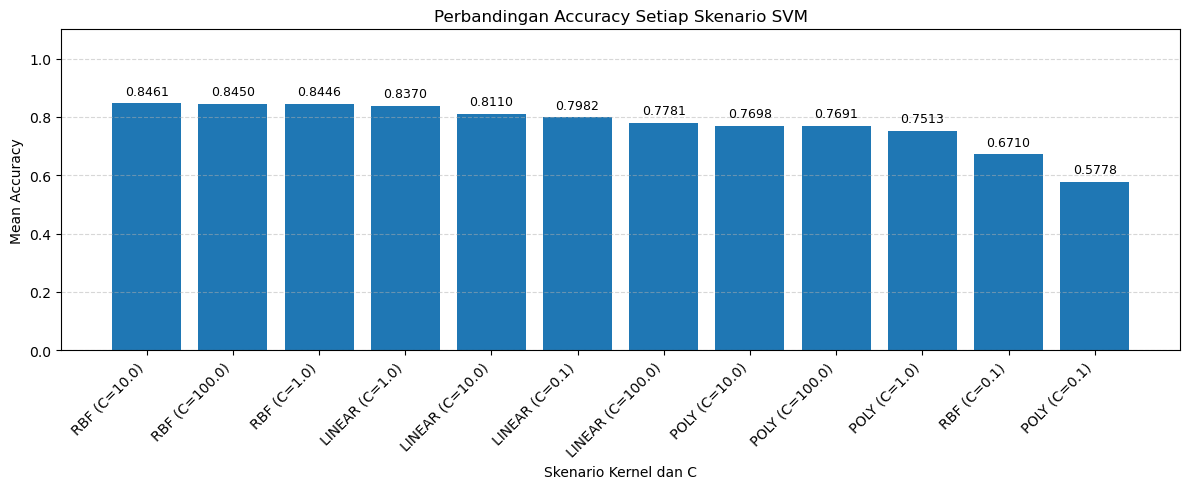

In [66]:
# Membuat label skenario
tabel_rekap["Skenario"] = (
    tabel_rekap["Kernel"] + " (C=" +
    tabel_rekap["C"].astype(str) + ")"
)

plt.figure(figsize=(12, 5))

# Simpan objek bar plot ke dalam variabel 'bars'
bars = plt.bar(
    tabel_rekap["Skenario"],
    tabel_rekap["Mean Accuracy"]
)

plt.title("Perbandingan Accuracy Setiap Skenario SVM")
plt.xlabel("Skenario Kernel dan C")
plt.ylabel("Mean Accuracy")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.1)  # Sedikit dinaikkan batas atasnya (1.1) agar teks angka tidak terpotong di atas
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Menambahkan angka di atas setiap batang
for bar in bars:
    height = bar.get_height()  # Mengambil nilai tinggi batang (Mean Accuracy)
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,  # Posisi X: di tengah-tengah lebar batang
        height + 0.02,                        # Posisi Y: sedikit di atas ujung batang
        f"{height:.4f}",                      # Format angka (4 desimal, misal: 0.8528)
        ha="center",                          # Penataan teks rata tengah horizontal
        va="bottom",                          # Penataan teks rata bawah vertikal
        fontsize=9
    )

plt.tight_layout()
plt.show()

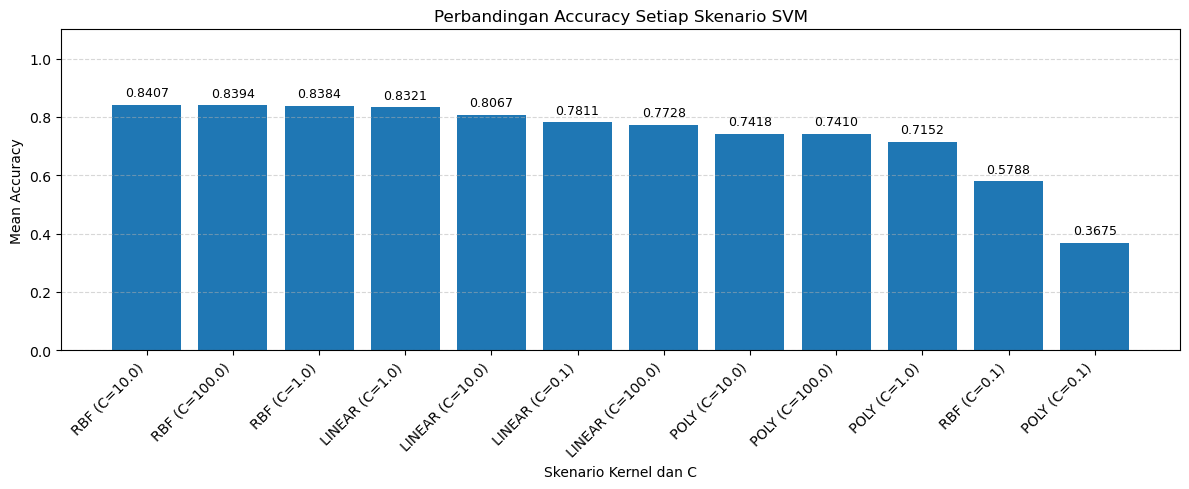

In [67]:
# Membuat label skenario
tabel_rekap["Skenario"] = (
    tabel_rekap["Kernel"] + " (C=" +
    tabel_rekap["C"].astype(str) + ")"
)

plt.figure(figsize=(12, 5))

# Simpan objek bar plot ke dalam variabel 'bars'
bars = plt.bar(
    tabel_rekap["Skenario"],
    tabel_rekap["Mean F1-Score"]
)

plt.title("Perbandingan Accuracy Setiap Skenario SVM")
plt.xlabel("Skenario Kernel dan C")
plt.ylabel("Mean Accuracy")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.1)  # Sedikit dinaikkan batas atasnya (1.1) agar teks angka tidak terpotong di atas
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Menambahkan angka di atas setiap batang
for bar in bars:
    height = bar.get_height()  # Mengambil nilai tinggi batang (Mean Accuracy)
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,  # Posisi X: di tengah-tengah lebar batang
        height + 0.02,                        # Posisi Y: sedikit di atas ujung batang
        f"{height:.4f}",                      # Format angka (4 desimal, misal: 0.8528)
        ha="center",                          # Penataan teks rata tengah horizontal
        va="bottom",                          # Penataan teks rata bawah vertikal
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [68]:
# Membuat pipeline model terbaik
final_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("svm", SVC(
        kernel=best_kernel,
        C=best_C,
        probability=True,
        random_state=42
    ))
])

# Melatih model dengan seluruh data training
final_model.fit(X_train, y_train)

print("Model terbaik berhasil dilatih!")
print("Kernel:", best_kernel)
print("C:", best_C)

Model terbaik berhasil dilatih!
Kernel: rbf
C: 10.0


In [69]:
# Prediksi data testing
y_pred = final_model.predict(X_test)

# Menghitung metrik evaluasi
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

# Membuat tabel hasil evaluasi
hasil_testing = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Precision (Macro)",
        "Recall (Macro)",
        "F1-Score (Macro)"
    ],
    "Nilai": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

hasil_testing["Nilai"] = hasil_testing["Nilai"].round(4)

print("=== HASIL EVALUASI DATA TESTING ===")
display(hasil_testing)

=== HASIL EVALUASI DATA TESTING ===


,Metrik,Nilai
0,Accuracy,0.8370
1,Precision (Macro),0.8359
2,Recall (Macro),0.8282
3,F1-Score (Macro),0.8312


In [70]:
print("=== CLASSIFICATION REPORT ===")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Hate Speech", "Hate Speech"],
    zero_division=0,
    digits=4
))

=== CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Hate Speech     0.8412    0.8848    0.8625      1485
    Hate Speech     0.8305    0.7716    0.8000      1086

       accuracy                         0.8370      2571
      macro avg     0.8359    0.8282    0.8312      2571
   weighted avg     0.8367    0.8370    0.8361      2571



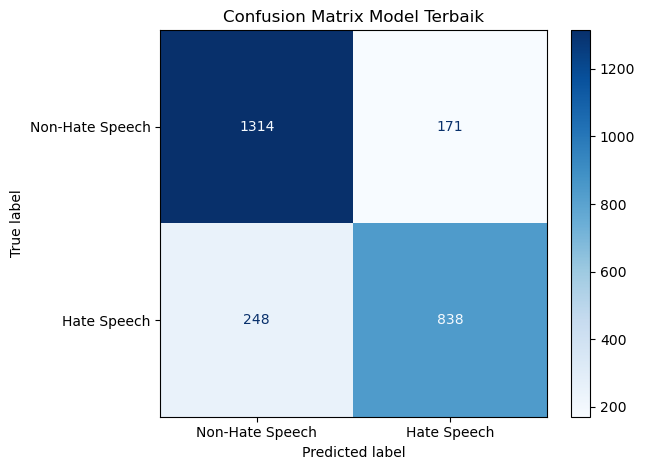

In [71]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Non-Hate Speech", "Hate Speech"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix Model Terbaik")
plt.tight_layout()
plt.show()

## **Saved Model dan Inference**

In [72]:
# Menyimpan model terbaik
model_path = "../model/best_svm_model.pkl"

joblib.dump(final_model, model_path)

print("Model berhasil disimpan!")
print("Lokasi:", model_path)

Model berhasil disimpan!
Lokasi: ../model/best_svm_model.pkl


In [79]:
import pandas as pd
import numpy as np
import re
import joblib
import nltk

from pathlib import Path
from nltk.tokenize import word_tokenize
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

nltk.download('punkt')
nltk.download('punkt_tab')

# ==============================
# 1. CLEANING
# ==============================

def cleaning_text(text):

    def decode_utf8_escape(match):
        hex_values = re.findall(r'\\x([0-9a-fA-F]{2})', match.group())
        byte_data = bytes(int(value, 16) for value in hex_values)

        return byte_data.decode('utf-8', errors='replace')

    text = re.sub(r'(?:\\x[0-9a-fA-F]{2})+', decode_utf8_escape, text)

    text = re.sub(r'\\[nrt]', ' ', text)
    text = re.sub(r'[\n\r\t]+', ' ', text)

    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'#([A-Za-z0-9_]+)', r'\1', text)
    text = re.sub(r'\bRT\b', ' ', text, flags=re.IGNORECASE)

    text = re.sub(r'[0-9]+', '', text)
    text = re.sub(r'[^\w\s]', ' ', text, flags=re.UNICODE)
    text = text.replace('_', ' ')

    text = re.sub(r'\bUSER\b', 'USER', text, flags=re.IGNORECASE)
    text = re.sub(r'(?:\bUSER\b\s*){2,}', 'USER ', text)

    text = re.sub(r'\s+', ' ', text).strip()

    return text


# ==============================
# 2. TOKENIZATION
# ==============================

def tokenizingText(text):
    return word_tokenize(text)


# ==============================
# 3. NORMALIZATION
# ==============================

# Load kamus normalisasi
alay_dict = pd.read_csv(
    "../dataset/raw/new_kamusalay.csv",
    encoding="latin-1",
    header=None
)

alay_dict.columns = ["original", "replacement"]

alay_dict_map = dict(
    zip(alay_dict["original"], alay_dict["replacement"])
)

def normalizationText(tokens):

    if isinstance(tokens, str):
        tokens = tokens.split()

    normalized_tokens = []

    for word in tokens:
        replacement = alay_dict_map.get(word, word)
        normalized_tokens.extend(replacement.split())

    return normalized_tokens


# ==============================
# 4. STOPWORD REMOVAL
# ==============================

factory = StopWordRemoverFactory()
stopwords = set(factory.get_stop_words())

def stopwordRemoval(tokens):
    return [
        word for word in tokens
        if word not in stopwords
    ]


# ==============================
# 5. STEMMING
# ==============================

factory = StemmerFactory()
stemmer = factory.create_stemmer()

def stemmingText(tokens):
    stems = [stemmer.stem(word) for word in tokens]
    return ' '.join(stems)

# Load model SVM terbaik
best_model_svm = joblib.load(
    "../model/best_svm_model.pkl"
)

print("Model SVM berhasil dimuat!")

## INFERENCE MODEL

def predict_hate_speech(tweet_text):

    # Preprocessing the input tweet
    cleaned_tweet = cleaning_text(tweet_text)
    casefolded_tweet = cleaned_tweet.lower()
    tokenized_tweet = tokenizingText(casefolded_tweet)
    normalized_tweet = normalizationText(tokenized_tweet)
    stopwords_removed_tweet = stopwordRemoval(normalized_tweet)
    stemmed_tweet = stemmingText(stopwords_removed_tweet)

    # Get prediction probabilities
    probabilities = best_model_svm.predict_proba([stemmed_tweet])[0]

    # Get the predicted class and confidence score
    predicted_index = np.argmax(probabilities)
    predicted_label = best_model_svm.classes_[predicted_index]
    confidence_score = probabilities[predicted_index]

    # Convert prediction into label
    if predicted_label == 1:
        result = "Hate Speech"
    else:
        result = "Non-Hate Speech"

    # Display prediction result
    print(f"Original Tweet: {tweet_text}")
    print(f"\nPreprocessed Tweet: {stemmed_tweet}")
    print(f"\nHasil Prediksi: {result}")
    print(f"Confidence Score: {confidence_score:.4f}")
    print(f"Confidence Percentage: {confidence_score * 100:.2f}%")


# Contoh penggunaan
user_tweet = input("Masukkan tweet Anda: ")
predict_hate_speech(user_tweet)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Model SVM berhasil dimuat!
Original Tweet: Hari ini cuacanya benar-benar cerah dan enak banget buat jalan-jalan sore di pantai.

Preprocessed Tweet: hari cuaca benar benar cerah enak banget buat jalan jalan sore pantai

Hasil Prediksi: Non-Hate Speech
Confidence Score: 0.9862
Confidence Percentage: 98.62%
